In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from typing import List, Tuple, Dict
from torchvision.io import read_image, ImageReadMode
import matplotlib.pyplot as plt
from torchinfo import summary
from torch.amp import autocast, GradScaler
import os
import cv2
import time
import torch
import numpy as np
from tqdm.auto import tqdm

def get_horizon_schedule(epoch: int) -> int:
    phase = epoch // 50
    K = 2 * (2 ** phase)
    return min(K, T - 1, 512)
    
def get_split_params(models, debug: bool = False):
    split_params = {'adam': [], 'muon': []}

    for model in models:
        for name, param in model.named_parameters():
            if name.endswith(".weight") and 'W_h' in name:
                split_params['muon'].append((name, param))
                if debug: print(name, param.shape, 'muon')
            elif 'bias' in name:
                split_params['adam'].append((name, param))
                if debug: print(name, param.shape, 'adam')
            elif name.endswith(".weight") and 'W_h' not in name:
                split_params['adam'].append((name, param))
                if debug: print(name, param.shape, 'adam')
            elif 'param' in name:
                split_params['adam'].append((name, param))
                if debug: print(name, param.shape, 'adam')
            else:
                    if debug: print(name, param.shape, 'NONE_MISSING')
        
    return split_params

print(torch.cuda.is_available())

True


In [ ]:
class CustomTransitionFunction(nn.Module):
    def __init__(self,hidden_size, init_weights: bool = True):
        super(CustomTransitionFunction, self).__init__()
        self.hidden_size=hidden_size
        self.W_hf=nn.Linear(hidden_size,hidden_size)
        self.W_hi=nn.Linear(hidden_size,hidden_size)
        self.W_ho=nn.Linear(hidden_size,hidden_size)
        self.W_hg=nn.Linear(hidden_size,hidden_size)
        if init_weights:
            self.init_weights()

    def init_weights(self) -> None:
        for name, param in self.named_parameters():
            if name.endswith(".weight") and 'W_h' in name:
                nn.init.orthogonal_(param)
            elif 'bias' in name:
                nn.init.zeros_(param)
        self.W_hf.bias.data.fill_(1.0)
        return

    def forward(self,h,c):
        f=F.sigmoid(self.W_hf(h))
        i=F.sigmoid(self.W_hi(h))
        o=F.sigmoid(self.W_ho(h))

        c_t=torch.tanh(self.W_hg(h))
        c=f*c+i*c_t

        h=o*torch.tanh(c)
        return h,c

class DepthwiseSeparableConv(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        kernel_size: int = 3,
    ):
        super().__init__()

        padding = kernel_size // 2

        self.depthwise = nn.Conv2d(
            in_channels,
            in_channels,
            kernel_size=kernel_size,
            padding=padding,
            groups=in_channels,
            bias=False,
        )

        self.pointwise = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=1,
            bias=True,
        )

        self.norm = nn.GroupNorm(
            num_groups=1,
            num_channels=out_channels,
        )

        self.act = nn.SiLU()

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        x = self.norm(x)
        x = self.act(x)
        return x


class FrameDecoder(nn.Module):
    def __init__(
        self,
        hidden_size: int = 64,
        output_height: int = 384,
        output_width: int = 512,
    ):
        super().__init__()

        self.output_height = output_height
        self.output_width = output_width

        self.base_channels = 8
        self.base_height = output_height // 16
        self.base_width = output_width // 16

        if output_height % 16 != 0:
            raise ValueError(
                "output_height must be divisible by 16"
            )

        if output_width % 16 != 0:
            raise ValueError(
                "output_width must be divisible by 16"
            )

        self.projection = nn.Linear(
            hidden_size,
            self.base_channels
            * self.base_height
            * self.base_width,
        )

        self.block1 = DepthwiseSeparableConv(8, 16)
        self.block2 = DepthwiseSeparableConv(16, 16)
        self.block3 = DepthwiseSeparableConv(16, 8)

        self.output = nn.Conv2d(
            8,
            1,
            kernel_size=1,
        )

    def forward(self, x):
        """
        Accepts:

            [B, hidden]
            [T, B, hidden]

        Returns:

            [B, 1, H, W]
            [T, B, 1, H, W]

        Output is logits. Do NOT apply sigmoid here.
        """

        original_shape = x.shape[:-1]

        x = x.reshape(-1, x.shape[-1])

        x = self.projection(x)

        x = x.reshape(
            -1,
            self.base_channels,
            self.base_height,
            self.base_width,
        )

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False,
        )
        x = self.block1(x)

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False,
        )
        x = self.block2(x)

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False,
        )
        x = self.block3(x)

        x = F.interpolate(
            x,
            scale_factor=2,
            mode="bilinear",
            align_corners=False,
        )

        x = self.output(x)

        x = x.reshape(
            *original_shape,
            1,
            self.output_height,
            self.output_width,
        )

        return x

class TrainingTableEmbeddings(nn.Module):
    def __init__(self, h_dim: int, c_dim: int, entries: int, init_weights: bool = True):
        super(TrainingTableEmbeddings, self).__init__()
        self.h_dim: int = h_dim
        self.c_dim: int = c_dim
        self.entries: int = entries

        self.h_table = nn.Embedding(num_embeddings=self.entries, embedding_dim=self.h_dim, max_norm=None)
        self.c_table = nn.Embedding(num_embeddings=self.entries, embedding_dim=self.c_dim, max_norm=None)

        self.init_weights()

    def init_weights(self) -> None:
        nn.init.xavier_normal_(self.h_table.weight)
        nn.init.xavier_normal_(self.c_table.weight)

    def forward(self, indices):
        return self.h_table(indices), self.c_table(indices)


In [3]:
class BadApple(torch.utils.data.Dataset):
    def __init__(self, dataset_path: str | Path):
        self.dataset_path = Path(dataset_path).resolve()

        if not self.dataset_path.exists():
            raise FileNotFoundError(
                f"Dataset path {self.dataset_path} does not exist"
            )

        self.frame_paths = sorted(
            p for p in self.dataset_path.iterdir() if p.is_file()
        )

        if not self.frame_paths:
            raise ValueError(f"No files found in {self.dataset_path}")

        self.frames = torch.stack([
            read_image(str(path), mode=ImageReadMode.GRAY)
            for path in self.frame_paths
        ])

    def __len__(self):
        return self.frames.shape[0]

    def __getitem__(self, index):
        return self.frames[index].float().div_(255.0)

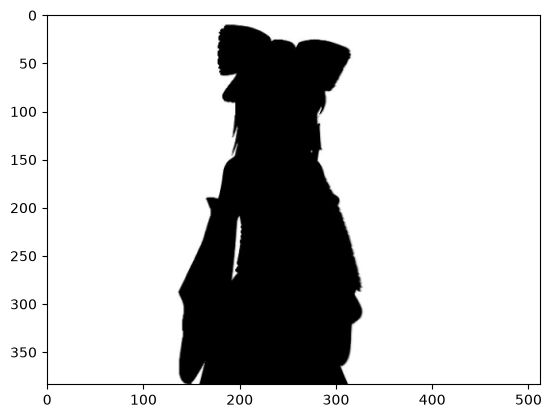

In [4]:
dataset = BadApple(dataset_path='frames')
image = dataset[150]
plt.imshow(image.squeeze(), cmap='gray')

In [5]:
if False:
    T = len(dataset)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    total_epochs = 500
    FRAME_BUDGET = 512
    HIDDEN_SIZE = 64
    H_DIM, C_DIM = HIDDEN_SIZE, HIDDEN_SIZE
    ENTRIES = T
    LEARNING_RATE = 0.001

    LAMBDA_DYN_H = 0.1
    LAMBDA_DYN_C = 0.1

    tte = TrainingTableEmbeddings(h_dim=H_DIM, c_dim=C_DIM, entries=ENTRIES).to(device)
    ctf = CustomTransitionFunction(hidden_size=HIDDEN_SIZE).to(device)
    fd = FrameDecoder().to(device)

    summary(
        fd, 
        input_size=(1, HIDDEN_SIZE),
        col_names=["input_size", "output_size", "num_params"],
        depth=3
    )

    summary(
        ctf, 
        input_size=[(16, HIDDEN_SIZE), (16, HIDDEN_SIZE)],
        col_names=["input_size", "output_size", "num_params"]
    )

    summary(
        tte, 
        input_size=(1,), 
        dtypes=[torch.long],
        col_names=["input_size", "output_size", "num_params",]
    )

In [6]:
use_amp = True
log_dir = "runs"
scaler = GradScaler('cuda', enabled=use_amp)
T = len(dataset)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
total_epochs = 650
FRAME_BUDGET = 512
HIDDEN_SIZE = 64
H_DIM, C_DIM = HIDDEN_SIZE, HIDDEN_SIZE
ENTRIES = T
LEARNING_RATE = 0.00001
DECODER_CHUNK_SIZE = 32
SCALE_FACTOR = 0.2
STATE_NOISE_STD = 0.005

LAMBDA_DECODE = 0.2
LAMBDA_DYN_H = 1.0
LAMBDA_DYN_C = 1.0


tte = TrainingTableEmbeddings(h_dim=H_DIM, c_dim=C_DIM, entries=ENTRIES).to(device)
ctf = CustomTransitionFunction(hidden_size=HIDDEN_SIZE).to(device)
fd = FrameDecoder().to(device)

split_params = get_split_params([tte, ctf, fd])

optimizer_adam = torch.optim.AdamW(
    [p for n, p in split_params['adam']], 
    lr=LEARNING_RATE,
    weight_decay=0.001
)
optimizer_muon = torch.optim.Muon(
    [p for n, p in split_params['muon']], 
    lr=0.005, 
    momentum=0.95
)

resume_from_checkpoint = True
checkpoint_path = "runs/last_model.pt"
start_epoch = 0
best_loss = float("inf")

if resume_from_checkpoint and os.path.exists(checkpoint_path):
    print(f"Loading checkpoint from: {checkpoint_path}")
    checkpoint: dict = torch.load(checkpoint_path, map_location=device)
    
    tte.load_state_dict(checkpoint["tte"])
    ctf.load_state_dict(checkpoint["ctf"])
    fd.load_state_dict(checkpoint["fd"])
    
    start_epoch = checkpoint.get("epoch", 0)
    best_loss = checkpoint.get("best_loss", checkpoint.get("loss", float("inf")))

    if "optimizer_adam" in checkpoint:
        optimizer_adam.load_state_dict(checkpoint["optimizer_adam"])
    if "optimizer_muon" in checkpoint:
        optimizer_muon.load_state_dict(checkpoint["optimizer_muon"])
    if "scaler" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler"])
        
    print(f"Resumed successfully! Starting at Epoch {start_epoch:03d} / {total_epochs}")
else:
    print(f"No checkpoint loaded. Starting fresh training from Epoch 000.")

tte.train()
ctf.train()
fd.train()

def scale_optimizer_momentum_state(optimizer, factor: float = 0.2, reset: bool = False):
    for group in optimizer.param_groups:
        for p in group["params"]:
            if p in optimizer.state:
                state = optimizer.state[p]
                
                # For Muon and SGD
                if "momentum_buffer" in state:
                    if reset or factor == 0.0:
                        state["momentum_buffer"].zero_()
                    else:
                        state["momentum_buffer"].mul_(factor)
                
                # For Adam / AdamW (exp_avg is the momentum buffer)
                if "exp_avg" in state:
                    if reset or factor == 0.0:
                        state["exp_avg"].zero_()
                    else:
                        state["exp_avg"].mul_(factor)


def unroll_ctf(ctf_module, h_init, c_init, steps):
    h_curr, c_curr = h_init, c_init

    h_list = [h_curr]
    c_list = [c_curr]

    h_curr = h_curr + torch.randn_like(h_curr) * STATE_NOISE_STD
    c_curr = c_curr + torch.randn_like(c_curr) * STATE_NOISE_STD

    for _ in range(steps):
        h_clean, c_clean = ctf_module(h_curr, c_curr)

        h_list.append(h_clean)
        c_list.append(c_clean)

        h_curr = h_clean + torch.randn_like(h_clean) * STATE_NOISE_STD
        c_curr = c_clean + torch.randn_like(c_clean) * STATE_NOISE_STD

    return torch.stack(h_list), torch.stack(c_list)

compiled_unroll = torch.compile(unroll_ctf)

frames_gpu = dataset.frames.to(device=device)

epoch_pbar = tqdm(range(start_epoch, total_epochs), desc="Training Progress")

for epoch in epoch_pbar:
    K = get_horizon_schedule(epoch)
    batch_size = max(1, FRAME_BUDGET // (K + 1))

    epoch_loss = 0.0
    epoch_recon_loss = 0.0
    epoch_dyn_h_loss = 0.0
    epoch_dyn_c_loss = 0.0

    max_start_idx = T - K
    perm = torch.randperm(max_start_idx, device=device)
    steps = max_start_idx // batch_size

    offsets = torch.arange(K + 1, device=device)
    
    step_pbar = tqdm(
        range(steps),
        desc=f"Epoch {epoch:03d} [K={K:3d}, B={batch_size:2d}]",
        leave=False
    )

    if epoch > 0 and epoch % 10 == 0:
        print(f"\n[Epoch {epoch:03d}] Scaling momentum buffers by {SCALE_FACTOR}...")
        scale_optimizer_momentum_state(optimizer_muon, reset=False)
        scale_optimizer_momentum_state(optimizer_adam, reset=False)


    for step in step_pbar:

        optimizer_adam.zero_grad(set_to_none=True)
        optimizer_muon.zero_grad(set_to_none=True)

        t_batch = perm[step * batch_size : (step + 1) * batch_size]
        indices = t_batch[:, None] + offsets[None, :]

        # Keep targets in uint8 on GPU and slice per chunk to save VRAM
        target_frames = frames_gpu[indices].transpose(0, 1)  # shape: [K+1, B, 1, H, W]

        with autocast('cuda', enabled=use_amp):
            h_current, c_current = tte.h_table(t_batch), tte.c_table(t_batch)

            h_states, c_states = compiled_unroll(ctf, h_current, c_current, K)

            table_indices = t_batch[:, None] + offsets[None, :]
            h_targets = tte.h_table(table_indices).transpose(0, 1)
            c_targets = tte.c_table(table_indices).transpose(0, 1)

            loss_dyn_h = F.mse_loss(
                h_states[1:],
                h_targets[1:],
            )

            loss_dyn_c = F.mse_loss(
                c_states[1:],
                c_targets[1:],
            )

            dyn_loss_total = (
                LAMBDA_DYN_H * loss_dyn_h
                + LAMBDA_DYN_C * loss_dyn_c
            )

            smooth_loss = (
                h_states[2:]
                - 2 * h_states[1:-1]
                + h_states[:-2]
            ).pow(2).mean() + (
                c_states[2:]
                - 2 * c_states[1:-1]
                + c_states[:-2]
            ).pow(2).mean()
        
        recon_loss = 0.0
        total_frames = K + 1
        chunk_size = DECODER_CHUNK_SIZE

        for i in range(0, total_frames, chunk_size):
            h_chunk = h_states[i:i + chunk_size]
            
            target_chunk = (
                target_frames[i:i + chunk_size]
                .float()
                .div_(255.0)
            )

            with autocast('cuda', enabled=use_amp):
                pred_chunk = fd(h_chunk)
                chunk_weight = h_chunk.size(0) / total_frames
                chunk_loss = F.binary_cross_entropy_with_logits(
                    pred_chunk,
                    target_chunk,
                )

            recon_loss = recon_loss + chunk_weight * chunk_loss

        total_loss = dyn_loss_total + smooth_loss + recon_loss * LAMBDA_DECODE

        scaler.scale(total_loss).backward()
        scaler.step(optimizer_adam)
        scaler.step(optimizer_muon)
        scaler.update()

        epoch_loss += total_loss.item()
        epoch_recon_loss += recon_loss.item()
        epoch_dyn_h_loss += loss_dyn_h.item()
        epoch_dyn_c_loss += loss_dyn_c.item()

        step_pbar.set_postfix(
            loss=f"{total_loss.item():.4f}",
            recon=f"{recon_loss.item():.4f}",
            dyn_h=f"{loss_dyn_h.item():.4f}",
            dyn_c=f"{loss_dyn_c.item():.4f}",
            smooth_loss=f"{smooth_loss.item():.4f}"
        )

    epoch_loss /= steps
    epoch_recon_loss /= steps
    epoch_dyn_h_loss /= steps
    epoch_dyn_c_loss /= steps

    epoch_pbar.set_postfix(
        loss=f"{epoch_loss:.5f}",
        best=f"{best_loss:.5f}",
        K=K
    )

    log_line = (
        f"Epoch {epoch:03d} | "
        f"K={K:4d} | "
        f"Batch={batch_size:3d} | "
        f"Loss={epoch_loss:.6f} | "
        f"Recon={epoch_recon_loss:.6f} | "
        f"DynH={epoch_dyn_h_loss:.6f} | "
        f"DynC={epoch_dyn_c_loss:.6f}"
    )
    tqdm.write(log_line)
    with open("logs.txt", "a") as f_log:
        f_log.write(log_line + "\n")
    
    is_best = epoch_loss < best_loss
    if is_best:
        best_loss = epoch_loss

    state_payload = {
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "best_loss": best_loss,
        "tte": tte.state_dict(),
        "ctf": ctf.state_dict(),
        "fd": fd.state_dict(),
        "optimizer_adam": optimizer_adam.state_dict(),
        "optimizer_muon": optimizer_muon.state_dict(),
        "scaler": scaler.state_dict(),
    }

    torch.save(state_payload, os.path.join(log_dir, "last_model.pt"))

    if is_best:
        torch.save(state_payload, os.path.join(log_dir, "best_model.pt"))
        print(f"  ⭐ New best model saved! (Loss: {best_loss:.6f})")


Loading checkpoint from: runs/last_model.pt
Resumed successfully! Starting at Epoch 650 / 650


Training Progress: 0it [00:00, ?it/s]

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HIDDEN_SIZE = 64
H_DIM, C_DIM = HIDDEN_SIZE, HIDDEN_SIZE
ENTRIES = len(dataset)

tte = TrainingTableEmbeddings(h_dim=H_DIM, c_dim=C_DIM, entries=ENTRIES).to(device)
ctf = CustomTransitionFunction(hidden_size=HIDDEN_SIZE).to(device)
fd = FrameDecoder(hidden_size=HIDDEN_SIZE, output_height=384, output_width=512).to(device)

checkpoint_path = "runs/last_model.pt"
checkpoint = torch.load(checkpoint_path, map_location=device)

tte.load_state_dict(checkpoint["tte"])
ctf.load_state_dict(checkpoint["ctf"])
fd.load_state_dict(checkpoint["fd"])

tte.eval()
ctf.eval()
fd.eval()

print(f"Loaded checkpoint from epoch {checkpoint.get('epoch', 'N/A')}")

In [ ]:
def visualize_autonomous_rollout(
    tte, 
    ctf, 
    fd, 
    dataset, 
    start_frame: int = 0, 
    num_frames: int | None = None, 
    fps: int = 30, 
    save_video_path: str | None = None,
    device: str = "cuda"
):
    """
    Real-time OpenCV visualizer comparing Ground Truth vs Autonomous Rollout.
    """
    tte.eval()
    ctf.eval()
    fd.eval()

    total_dataset_frames = len(dataset)
    if num_frames is None:
        num_frames = total_dataset_frames - start_frame
    else:
        num_frames = min(num_frames, total_dataset_frames - start_frame)

    window_name = "Bad Apple!! Autonomous Rollout Visualizer"
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(window_name, 1024, 460)

    
    video_writer = None
    if save_video_path:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        
        video_writer = cv2.VideoWriter(save_video_path, fourcc, fps, (1024, 444))
        print(f"Recording video to: {save_video_path}")

    
    with torch.no_grad():
        t0 = torch.tensor([start_frame], device=device)
        h_curr = tte.h_table(t0)
        c_curr = tte.c_table(t0)

    paused = False
    step_forward = False
    frame_idx = 0
    prev_time = time.time()

    print("\nVisualizer running! Controls:")
    print(" [SPACE] : Pause / Resume")
    print(" [D]     : Step 1 frame forward (while paused)")
    print(" [R]     : Restart rollout from start")
    print(" [S]     : Save comparison snapshot")
    print(" [Q/ESC] : Quit\n")

    try:
        while frame_idx < num_frames:
            current_t = start_frame + frame_idx

            gt_tensor = dataset[current_t].squeeze() 
            gt_img = (gt_tensor.numpy() * 255).astype(np.uint8)
            gt_bgr = cv2.cvtColor(gt_img, cv2.COLOR_GRAY2BGR)

            with torch.no_grad():
                pred_logit = fd(h_curr)
                pred_tensor = torch.sigmoid(pred_logit).squeeze().cpu()
                pred_img = (pred_tensor.numpy() * 255).astype(np.uint8)
                pred_bgr = cv2.cvtColor(pred_img, cv2.COLOR_GRAY2BGR)

                mse_error = torch.mean((pred_tensor - gt_tensor) ** 2).item()

                if not paused or step_forward:
                    h_curr, c_curr = ctf(h_curr, c_curr)

            canvas = np.hstack([gt_bgr, pred_bgr])

            header = np.zeros((60, canvas.shape[1], 3), dtype=np.uint8)
            header[:] = (25, 25, 25) 

            fps_actual = 1.0 / max(1e-5, (time.time() - prev_time))
            prev_time = time.time()
            time_str = f"{current_t // (fps * 60):02d}:{(current_t // fps) % 60:02d}.{(current_t % fps):02d}"
            
            info_left = f"Frame: {current_t:04d}/{total_dataset_frames} | Time: {time_str} | FPS: {fps_actual:.1f}"
            cv2.putText(header, info_left, (15, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2, cv2.LINE_AA)

            status_str = "[PAUSED]" if paused else "[RUNNING]"
            status_color = (0, 165, 255) if paused else (0, 255, 0)
            info_right = f"MSE: {mse_error:.5f}  {status_str}"
            cv2.putText(header, info_right, (canvas.shape[1] - 320, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.65, status_color, 2, cv2.LINE_AA)

            cv2.putText(canvas, "Ground Truth", (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
            cv2.putText(canvas, "Autonomous Rollout (Recursive ctf)", (512 + 15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)

            cv2.line(canvas, (512, 0), (512, 384), (50, 50, 50), 2)

            full_frame = np.vstack([header, canvas])

            if video_writer:
                video_writer.write(full_frame)

            cv2.imshow(window_name, full_frame)

            step_forward = False

            delay = 1 if paused else max(1, int(1000 / fps))
            key = cv2.waitKey(delay) & 0xFF

            if key == ord('q') or key == 27:  
                print("Visualizer stopped by user.")
                break
            elif key == ord(' '):  
                paused = not paused
            elif key == ord('d') or key == 83:
                if paused:
                    step_forward = True
                    frame_idx += 1
            elif key == ord('r'):  
                frame_idx = 0
                with torch.no_grad():
                    t0 = torch.tensor([start_frame], device=device)
                    h_curr = tte.h_table(t0)
                    c_curr = tte.c_table(t0)
                print("Restarted rollout from t=0")
                continue
            elif key == ord('s'):  
                snap_name = f"snapshot_frame_{current_t}.png"
                cv2.imwrite(snap_name, full_frame)
                print(f"Saved snapshot: {snap_name}")

            if not paused:
                frame_idx += 1

    finally:
        if video_writer:
            video_writer.release()
            print(f"Video saved to {save_video_path}")
        cv2.destroyAllWindows()
        cv2.waitKey(1)


In [ ]:
visualize_autonomous_rollout(
    tte=tte,
    ctf=ctf,
    fd=fd,
    dataset=dataset,
    start_frame=0,
    num_frames=len(dataset),
    fps=30,
    save_video_path="bad_apple_rollout.mp4",
    device=device
)

In [ ]:
def visualize_table_reconstruction(
    tte, 
    fd, 
    dataset, 
    start_frame: int = 0, 
    num_frames: int = None, 
    fps: int = 30, 
    save_video_path: str = None,
    device: str = "cuda"
):
    """
    Real-time visualizer for Direct Table Reconstruction (Embedding Table -> FrameDecoder).
    No RNN/transition function is used.
    """
    tte.eval()
    fd.eval()

    total_dataset_frames = len(dataset)
    if num_frames is None:
        num_frames = total_dataset_frames - start_frame
    else:
        num_frames = min(num_frames, total_dataset_frames - start_frame)

    window_name = "Bad Apple!! Direct Table Reconstruction (Decoder Only)"
    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(window_name, 1024, 460)


    trackbar_state = {"frame_idx": start_frame, "updated_by_user": False}

    def on_trackbar(val):
        trackbar_state["frame_idx"] = val
        trackbar_state["updated_by_user"] = True

    cv2.createTrackbar("Timeline", window_name, start_frame, total_dataset_frames - 1, on_trackbar)


    video_writer = None
    if save_video_path:
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        video_writer = cv2.VideoWriter(save_video_path, fourcc, fps, (1024, 444))
        print(f"Recording video to: {save_video_path}")

    paused = False
    current_t = start_frame
    prev_time = time.time()

    print("\nVisualizer running! Controls:")
    print(" [Trackbar] : Scrub to any frame")
    print(" [SPACE]    : Pause / Play")
    print(" [A] / [D]  : Step 1 frame backward / forward")
    print(" [R]        : Jump to start (t=0)")
    print(" [S]        : Save comparison screenshot")
    print(" [Q/ESC]    : Quit\n")

    try:
        while current_t < total_dataset_frames:
        
            if trackbar_state["updated_by_user"]:
                current_t = trackbar_state["frame_idx"]
                trackbar_state["updated_by_user"] = False

        
            gt_tensor = dataset[current_t].squeeze()
            gt_img = (gt_tensor.numpy() * 255).astype(np.uint8)
            gt_bgr = cv2.cvtColor(gt_img, cv2.COLOR_GRAY2BGR)

        
            with torch.no_grad():
                t_tensor = torch.tensor([current_t], device=device)
                h_table_val = tte.h_table(t_tensor)
                
                pred_logit = fd(h_table_val)
                pred_tensor = torch.sigmoid(pred_logit).squeeze().cpu()
                pred_img = (pred_tensor.numpy() * 255).astype(np.uint8)
                pred_bgr = cv2.cvtColor(pred_img, cv2.COLOR_GRAY2BGR)

                mse_error = torch.mean((pred_tensor - gt_tensor) ** 2).item()

        
            canvas = np.hstack([gt_bgr, pred_bgr])

        
            header = np.zeros((60, canvas.shape[1], 3), dtype=np.uint8)
            header[:] = (25, 25, 25)

            fps_actual = 1.0 / max(1e-5, (time.time() - prev_time))
            prev_time = time.time()
            time_str = f"{current_t // (fps * 60):02d}:{(current_t // fps) % 60:02d}.{(current_t % fps):02d}"

            info_left = f"Frame: {current_t:04d}/{total_dataset_frames} | Time: {time_str} | FPS: {fps_actual:.1f}"
            cv2.putText(header, info_left, (15, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2, cv2.LINE_AA)

            status_str = "[PAUSED]" if paused else "[PLAYING]"
            status_color = (0, 165, 255) if paused else (0, 255, 0)
            info_right = f"MSE: {mse_error:.5f}  {status_str}"
            cv2.putText(header, info_right, (canvas.shape[1] - 330, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.65, status_color, 2, cv2.LINE_AA)

            cv2.putText(canvas, "Ground Truth", (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
            cv2.putText(canvas, "Direct Table Reconstruction (fd(h_t))", (512 + 15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
            cv2.line(canvas, (512, 0), (512, 384), (50, 50, 50), 2)

            full_frame = np.vstack([header, canvas])

            if video_writer:
                video_writer.write(full_frame)

            cv2.imshow(window_name, full_frame)
            cv2.setTrackbarPos("Timeline", window_name, current_t)

        
            delay = 1 if paused else max(1, int(1000 / fps))
            key = cv2.waitKey(delay) & 0xFF

            if key == ord('q') or key == 27:
                print("Visualizer stopped.")
                break
            elif key == ord(' '):
                paused = not paused
            elif key == ord('d') or key == 83:
                if paused and current_t < total_dataset_frames - 1:
                    current_t += 1
            elif key == ord('a') or key == 81:
                if paused and current_t > 0:
                    current_t -= 1
            elif key == ord('r'):
                current_t = 0
            elif key == ord('s'):
                snap_name = f"table_recon_frame_{current_t}.png"
                cv2.imwrite(snap_name, full_frame)
                print(f"Saved snapshot: {snap_name}")

            if not paused:
                current_t += 1

    finally:
        if video_writer:
            video_writer.release()
            print(f"Video saved to {save_video_path}")
        cv2.destroyAllWindows()
        cv2.waitKey(1)


In [ ]:
visualize_table_reconstruction(
    tte=tte,
    fd=fd,
    dataset=dataset,
    start_frame=0,
    num_frames=len(dataset),
    fps=30,
    save_video_path="bad_apple_table_reconstruction.mp4",
    device=device.type
)
